In [1]:
# 1. import, visualization setup
import os, sys
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3})
COLORS = {'gate_30': '#2a6fdb', 'gate_40': '#e07b39'}
rng = np.random.default_rng(42)
N_DRAWS = 200_000   # posterior Monte Carlo draws

In [2]:
# 2. Mount drive, create directories
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
  from google.colab import drive
  drive.mount('/content/drive')
PROJECT_ROOT = Path('/content/drive/MyDrive/cookie-cats-bayesian-ab')
DATA_DIR, FIG_DIR, RESULTS_DIR, CODE_DIR = (PROJECT_ROOT / d for d in ['data', 'figures', 'results', 'code'])
for d in [DATA_DIR, FIG_DIR, RESULTS_DIR, CODE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    # Save the current figure to figures/ and show it inline
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def save_table(frame, name):
    frame.to_csv(RESULTS_DIR / f"{name}.csv")

print("Project root:", PROJECT_ROOT.resolve())

Mounted at /content/drive
Project root: /content/drive/MyDrive/cookie-cats-bayesian-ab


In [3]:
# 3. download data, 2 fallback options
DATA_URL = ("https://raw.githubusercontent.com/ryanschaub/"
            "Mobile-Games-A-B-Testing-with-Cookie-Cats/master/cookie_cats.csv")

DATA_PATH = DATA_DIR / "cookie_cats.csv"

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    try:
        df = pd.read_csv(DATA_URL)
    except Exception as e:
        print("Public URL failed:", e)
        # --- Fallback A: Kaggle API -------------------------------------
        # from google.colab import files; files.upload()   # pick kaggle.json
        # !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
        # !kaggle datasets download -d yufengsui/mobile-games-ab-testing --unzip
        # --- Fallback B: manual upload ----------------------------------
        # from google.colab import files; files.upload()   # pick cookie_cats.csv
        # df = pd.read_csv("cookie_cats.csv")
        raise
    df.to_csv(DATA_PATH, index=False)
    print("Saved raw data to", DATA_PATH)

print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [4]:
# 4. data check
print("Missing values:\n", df.isna().sum(), sep="")
print("\nDuplicate user ids:", df["userid"].duplicated().sum())
df.describe()

Missing values:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Duplicate user ids: 0


,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000


In [5]:
# 5. Sample ratio mismatch (SRM)
counts = df["version"].value_counts().sort_index()
srm_chi2, srm_p = stats.chisquare(counts.values)
print(counts.to_string())
print(f"\nSRM chi-square = {srm_chi2:.2f}, p = {srm_p:.4f}")

version
gate_30    44700
gate_40    45489

SRM chi-square = 6.90, p = 0.0086


SRM p value (p = 0.0086) is well below standard threshold (p = 0.05), indicating that the 44,700 vs. 45,489 split is unlikely to be pure chance.

In [6]:
# 6. remove outliers
print(df.nlargest(5, "sum_gamerounds")[["userid", "version", "sum_gamerounds"]])
df = df[df["sum_gamerounds"] < 10_000].copy()
print("\nRows after removing outlier:", len(df))

        userid  version  sum_gamerounds
57702  6390605  gate_30           49854
7912    871500  gate_30            2961
29417  3271615  gate_40            2640
43671  4832608  gate_30            2438
48188  5346171  gate_40            2294

Rows after removing outlier: 90188


In [7]:
# 7. exploratory analysis
summary = (df.groupby("version")
             .agg(users=("userid", "size"),
                  retention_1=("retention_1", "mean"),
                  retention_7=("retention_7", "mean"),
                  mean_rounds=("sum_gamerounds", "mean"),
                  median_rounds=("sum_gamerounds", "median")))
summary.style.format({"retention_1": "{:.2%}", "retention_7": "{:.2%}",
                      "mean_rounds": "{:.1f}", "median_rounds": "{:.0f}"})

,users,retention_1,retention_7,mean_rounds,median_rounds
version,,,,,
gate_30,44699,44.82%,19.02%,51.3,17
gate_40,45489,44.23%,18.20%,51.3,16


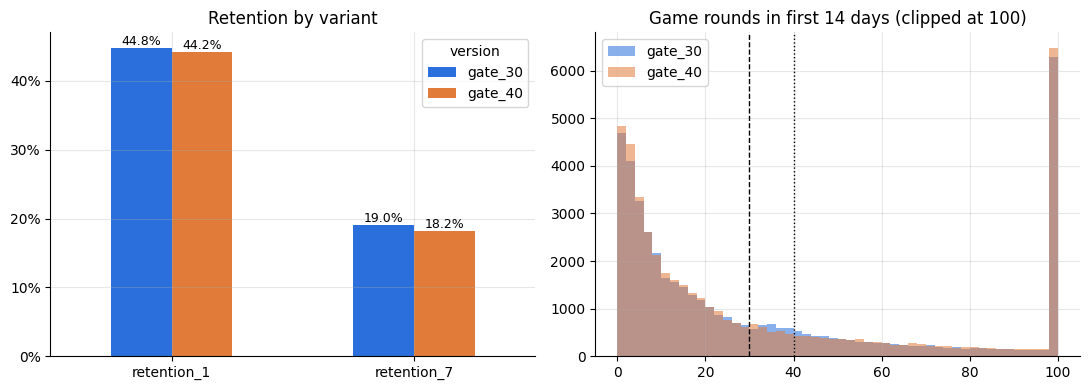

63% of players played fewer than 30 rounds, so they likely never saw either gate.


In [8]:
# 8. retention rate, and n of game rounds
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ret = df.groupby("version")[["retention_1", "retention_7"]].mean().T
ret.plot.bar(ax=axes[0], color=[COLORS["gate_30"], COLORS["gate_40"]], rot=0)
axes[0].set_title("Retention by variant")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
for c in axes[0].containers:
    axes[0].bar_label(c, fmt=lambda v: f"{v:.1%}", fontsize=9)

# How many players never reach the gate?
bins = np.arange(0, 101, 2)
for v, g in df.groupby("version"):
    axes[1].hist(g["sum_gamerounds"].clip(upper=100), bins=bins, alpha=0.55,
                 label=v, color=COLORS[v])
axes[1].axvline(30, ls="--", c="k", lw=1); axes[1].axvline(40, ls=":", c="k", lw=1)
axes[1].set_title("Game rounds in first 14 days (clipped at 100)")
axes[1].legend()
plt.tight_layout(); save_fig("01_retention_and_game_rounds")

share_under_30 = (df["sum_gamerounds"] < 30).mean()
print(f"{share_under_30:.0%} of players played fewer than 30 rounds, "
      "so they likely never saw either gate.")

More than half of players stop before round 30. The measured effect is therefore diluted; the effect on players who actually reach the gate is larger.

In [9]:
# 9. Two-proportion z-test for each retention metric, A = gate_30 (control) and B = gate_40 (treatment)
def ztest_two_prop(x_a, n_a, x_b, n_b, alpha=0.05):
  p_a, p_b = x_a / n_a, x_b / n_b
  p_pool = (x_a + x_b) / (n_a + n_b)
  se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
  z = (p_b - p_a) / se_pool # a negative difference means the new gate placement is worse
  p_value = 2 * stats.norm.sf(abs(z)) # survival func
  se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)   # standard error, unpooled for the CI
  zc = stats.norm.ppf(1 - alpha / 2) # 95% CI with alpha 0.05
  diff = p_b - p_a
  return dict(p_A=p_a, p_B=p_b, diff=diff, ci_low=diff - zc * se,
              ci_high=diff + zc * se, z=z, p_value=p_value)

def counts_for(metric):
    g = df.groupby("version")[metric].agg(["sum", "count"])
    return (int(g.loc["gate_30", "sum"]), int(g.loc["gate_30", "count"]),
            int(g.loc["gate_40", "sum"]), int(g.loc["gate_40", "count"]))

freq = pd.DataFrame({m: ztest_two_prop(*counts_for(m)) for m in ["retention_1", "retention_7"]}).T
save_table(freq, "frequentist_tests")
freq.style.format({"p_A": "{:.2%}", "p_B": "{:.2%}", "diff": "{:+.2%}", "ci_low": "{:+.2%}",
                   "ci_high": "{:+.2%}", "z": "{:.2f}", "p_value": "{:.4f}"})

,p_A,p_B,diff,ci_low,ci_high,z,p_value
retention_1,44.82%,44.23%,-0.59%,-1.24%,+0.06%,-1.79,0.0739
retention_7,19.02%,18.20%,-0.82%,-1.33%,-0.31%,-3.16,0.0016


Retention_1: p = 0.074, not statistically significant at the standard 95% confidence level (p < 0.05). Cannot confidently say this minor drop was caused by the change rather than random chance.

Retention_7: p = 0.0016, statistically highly significant (p < 0.01). A p-value of 0.16% means that if there were no real difference, a gap of this size would only occur 0.16% of the time. The new gate is associated with a genuine, measurable decrease in the long-term user retention.

However, a p-value does not tell us the probability that gate_40 is worse, or how much we lose by adopting it. The Bayesian analysis below addresses these questions directly.

In [10]:
# 10. Bayesian analysis (Beta-Binomial)
def bayesian_ab(x_a, n_a, x_b, n_b, prior=(1, 1), draws=N_DRAWS, seed=0):
  # Beta-Binomial A/B test. Returns summary dict and posterior samples.
  r = np.random.default_rng(seed)
  a0, b0 = prior
  pa = r.beta(a0 + x_a, b0 + n_a - x_a, draws)
  pb = r.beta(a0 + x_b, b0 + n_b - x_b, draws)
  diff = pb - pa
  lift = diff / pa # relative lift of B over A
  out = dict(
    mean_A=pa.mean(), mean_B=pb.mean(),
    prob_B_better=(pb > pa).mean(),
    diff_mean=diff.mean(),
    diff_ci_low=np.quantile(diff, 0.025), diff_ci_high=np.quantile(diff, 0.975),
    lift_mean=lift.mean(),
    lift_ci_low=np.quantile(lift, 0.025), lift_ci_high=np.quantile(lift, 0.975),
    loss_choose_B=np.maximum(pa - pb, 0).mean(),
    loss_choose_A=np.maximum(pb - pa, 0).mean(),
  )
  return out, dict(pa=pa, pb=pb, diff=diff, lift=lift)

bayes, samples = {}, {}
for m in ["retention_1", "retention_7"]:
    bayes[m], samples[m] = bayesian_ab(*counts_for(m))

bayes_df = pd.DataFrame(bayes).T
save_table(bayes_df, "bayesian_summary")
pct = "{:.2%}".format
bayes_df.style.format({c: pct for c in bayes_df.columns} |
                      {"loss_choose_B": "{:.4%}", "loss_choose_A": "{:.4%}"})

,mean_A,mean_B,prob_B_better,diff_mean,diff_ci_low,diff_ci_high,lift_mean,lift_ci_low,lift_ci_high,loss_choose_B,loss_choose_A
retention_1,44.82%,44.23%,3.68%,-0.59%,-1.24%,0.06%,-1.32%,-2.74%,0.13%,0.5975%,0.0049%
retention_7,19.02%,18.20%,0.09%,-0.82%,-1.33%,-0.31%,-4.30%,-6.88%,-1.65%,0.8189%,0.0001%


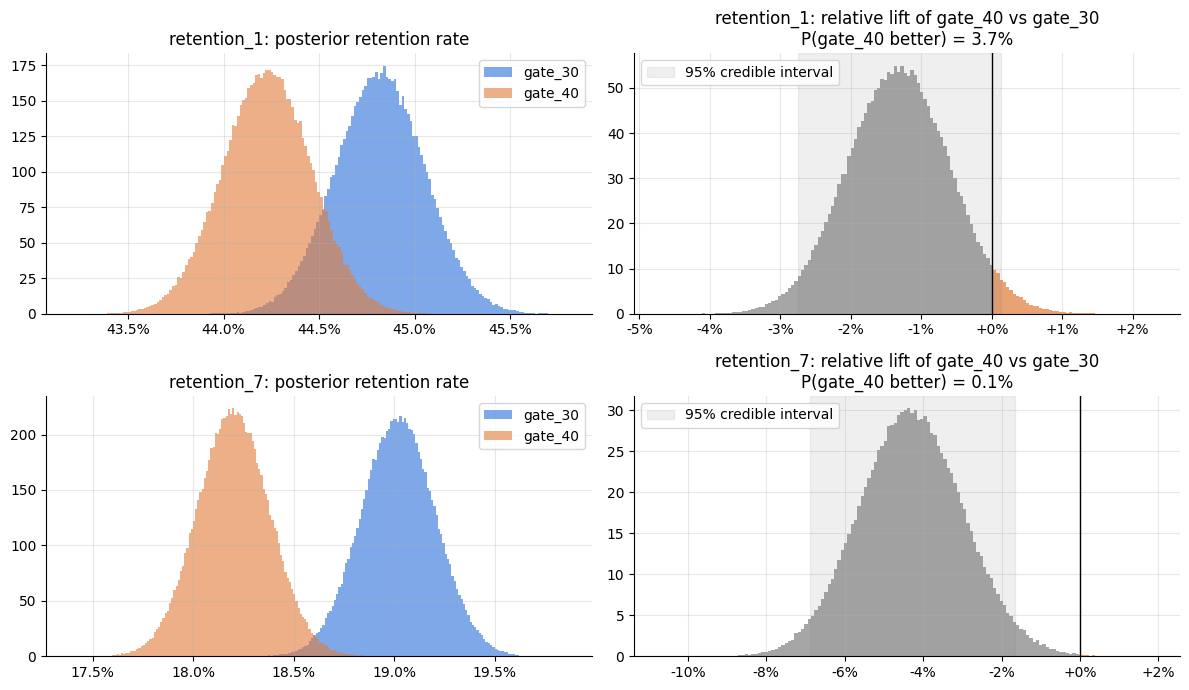

In [11]:
# 11. Visualization
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, m in enumerate(["retention_1", "retention_7"]):
    s = samples[m]
    ax = axes[row, 0]
    for key, v in [("pa", "gate_30"), ("pb", "gate_40")]:
        ax.hist(s[key], bins=150, density=True, alpha=0.6, color=COLORS[v], label=v)
    ax.set_title(f"{m}: posterior retention rate"); ax.legend()
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))

    ax = axes[row, 1]
    lift = s["lift"]
    n, bins, patches = ax.hist(lift, bins=150, density=True, color="grey", alpha=0.7)
    for p, left in zip(patches, bins[:-1]):
        if left > 0:
            p.set_facecolor(COLORS["gate_40"])
    lo, hi = np.quantile(lift, [0.025, 0.975])
    ax.axvline(0, c="k", lw=1)
    ax.axvspan(lo, hi, color="grey", alpha=0.12, label="95% credible interval")
    ax.set_title(f"{m}: relative lift of gate_40 vs gate_30\n"
                 f"P(gate_40 better) = {bayes[m]['prob_B_better']:.1%}")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
    ax.legend()
plt.tight_layout(); save_fig("02_posteriors_and_lift")

In [12]:
# 12. Summary of Block 10 results
for m in ["retention_1", "retention_7"]:
    b = bayes[m]
    print(f"--- {m} ---")
    print(f"P(gate_40 > gate_30)           = {b['prob_B_better']:.1%}")
    print(f"Relative lift of gate_40       = {b['lift_mean']:+.2%} "
          f"(95% CrI {b['lift_ci_low']:+.2%} to {b['lift_ci_high']:+.2%})")
    print(f"Expected loss if we ship 40    = {b['loss_choose_B']*100:.3f} pp of retention")
    print(f"Expected loss if we keep 30    = {b['loss_choose_A']*100:.4f} pp of retention\n")

--- retention_1 ---
P(gate_40 > gate_30)           = 3.7%
Relative lift of gate_40       = -1.32% (95% CrI -2.74% to +0.13%)
Expected loss if we ship 40    = 0.597 pp of retention
Expected loss if we keep 30    = 0.0049 pp of retention

--- retention_7 ---
P(gate_40 > gate_30)           = 0.1%
Relative lift of gate_40       = -4.30% (95% CrI -6.88% to -1.65%)
Expected loss if we ship 40    = 0.819 pp of retention
Expected loss if we keep 30    = 0.0001 pp of retention



Expected loss is almost zero if we choose gate 30.

In [13]:
# 13. Decision rule: expected loss vs. a “threshold of caring”. ε = 0.1 % here
EPSILON = 0.001

for m in ["retention_1", "retention_7"]:
    b = bayes[m]
    if b["loss_choose_A"] < EPSILON and b["loss_choose_A"] <= b["loss_choose_B"]:
        verdict = "keep gate_30"
    elif b["loss_choose_B"] < EPSILON:
        verdict = "ship gate_40"
    else:
        verdict = "inconclusive: keep collecting data"
    print(f"{m:12s}  loss(keep 30) = {b['loss_choose_A']*100:.4f} pp   "
          f"loss(ship 40) = {b['loss_choose_B']*100:.3f} pp   ->  {verdict}")

retention_1   loss(keep 30) = 0.0049 pp   loss(ship 40) = 0.597 pp   ->  keep gate_30
retention_7   loss(keep 30) = 0.0001 pp   loss(ship 40) = 0.819 pp   ->  keep gate_30


In [14]:
# 14. Prior sensitivity test. Choose four different sets
# (1) Beta(1,1) no info, flat
# (2) Beta(0.5,0.5) standard objective prior for binomial proportions, u-shape
# (3) Beta(20,80) weak prior
# (4) Beta(2000,8000) strong prior
# run this on the full data and on a random 500 players per arm
PRIORS = {"Uniform Beta(1,1)": (1, 1), "Jeffreys Beta(.5,.5)": (0.5, 0.5),
          "Weak Beta(20,80)": (20, 80), "Strong Beta(2000,8000)": (2000, 8000)}

def counts_from(frame, metric):
    g = frame.groupby("version")[metric].agg(["sum", "count"])
    return (int(g.loc["gate_30", "sum"]), int(g.loc["gate_30", "count"]),
            int(g.loc["gate_40", "sum"]), int(g.loc["gate_40", "count"]))

small = df.groupby("version").sample(500, random_state=1)

rows = []
for label, frame in [("Full data (~45k/arm)", df), ("Random 500/arm", small)]:
    c = counts_from(frame, "retention_7")
    for name, prior in PRIORS.items():
        b, _ = bayesian_ab(*c, prior=prior, draws=100_000)
        rows.append(dict(sample=label, prior=name, P_gate40_better=b["prob_B_better"],
                         lift_mean=b["lift_mean"], lift_ci_low=b["lift_ci_low"],
                         lift_ci_high=b["lift_ci_high"], loss_ship_40=b["loss_choose_B"]))
sens = pd.DataFrame(rows).set_index(["sample", "prior"])
save_table(sens, "prior_sensitivity")
sens.style.format({"P_gate40_better": "{:.1%}", "lift_mean": "{:+.2%}", "lift_ci_low": "{:+.2%}",
                   "lift_ci_high": "{:+.2%}", "loss_ship_40": "{:.3%}"})

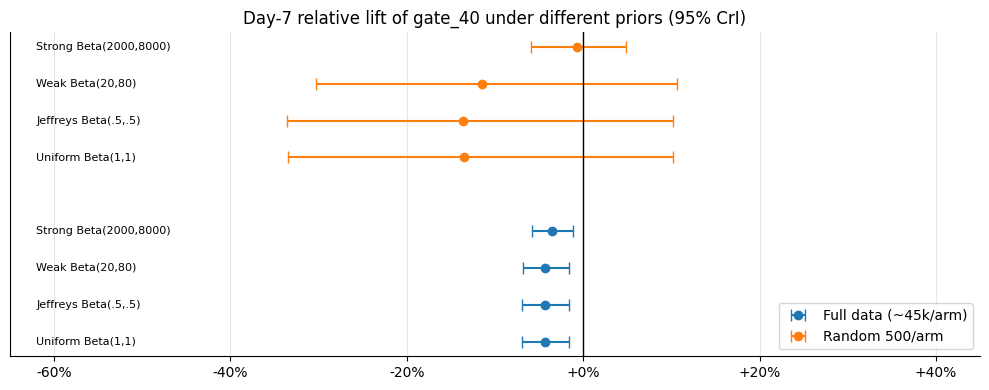

In [15]:
# 15. Visualization 4 priors
fig, ax = plt.subplots(figsize=(10, 4))
for i, (label, grp) in enumerate(sens.groupby(level=0, sort=False)):
    y = np.arange(len(grp)) + i * (len(grp) + 1)
    ax.errorbar(grp["lift_mean"], y,
                xerr=[grp["lift_mean"] - grp["lift_ci_low"], grp["lift_ci_high"] - grp["lift_mean"]],
                fmt="o", capsize=4, label=label)
    for yy, p in zip(y, grp.index.get_level_values(1)):
        ax.text(-0.62, yy, p, va="center", fontsize=8)
ax.axvline(0, c="k", lw=1)
ax.set_yticks([]); ax.set_xlim(-0.65, 0.45)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_title("Day-7 relative lift of gate_40 under different priors (95% CrI)")
ax.legend(loc="lower right"); plt.tight_layout(); save_fig("03_prior_sensitivity")

With ~45k players per arm, the data overwhelms any reasonable prior: the uniform, Jeffreys and weak priors give practically identical answers. Even the strong skeptical prior (worth 10,000 fake players per arm, all at the same rate) only shrinks the lift a little toward zero (from -4.3% to -3.5%) and still points the same way. With only 500 players per arm the intervals are wide and the strong prior dominates, which is exactly when the prior choice matters.

Mann-Whitney U p-value = 0.0509
Mean rounds:   gate_30 51.35, gate_40 51.30; diff -0.05 (95% CrI -1.43 to +1.35); P(gate_40 higher) = 46.1%
Median rounds: gate_30 17, gate_40 16; P(gate_40 higher median) = 0.1%


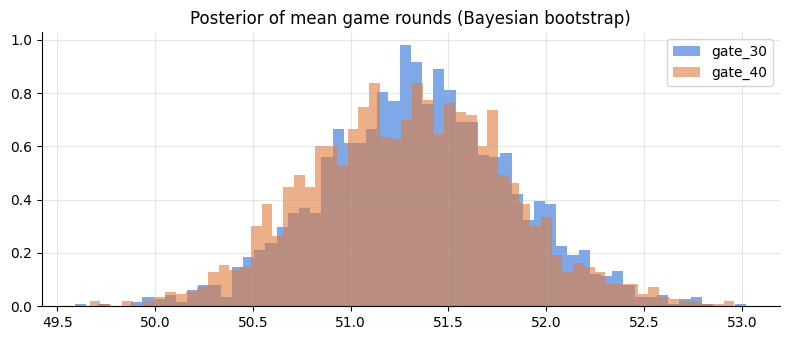

In [16]:
# 16. continuous engagement data
# sum_gamerounds is heavily skewed with extreme values, so t-test on the mean is fragile
# With 45 k users the CLT holds, but a few heavy players can swing the mean
# a frequentist Mann-Whitney U test and a Bayesian Bootstrap simulation to evaluate both the mean and median
a = df.loc[df.version == 'gate_30', 'sum_gamerounds'].to_numpy()
b = df.loc[df.version == 'gate_40', 'sum_gamerounds'].to_numpy()
u_stat, u_p = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Mann-Whitney U p-value = {u_p:.4f}")

def bayes_bootstrap(x, n_rep=2000, seed=0):
  # Posterior draws of the mean and median via Dirichlet-weighted resampling.
  # Players with the same value are grouped so each replicate is cheap.
  r = np.random.default_rng(seed)
  vals, count = np.unique(x, return_counts=True)
  means, medians = np.empty(n_rep), np.empty(n_rep) # (count) players played (vals) round
  for i in range(n_rep):
    # Sum of `count` iid Exp(1) is Gamma(count, 1): equivalent to Dirichlet weights per player
    w = r.gamma(count, 1.0)
    w /= w.sum()
    means[i] = (w * vals).sum()
    medians[i] = vals[np.searchsorted(np.cumsum(w), 0.5)]
  return means, medians

mA, medA = bayes_bootstrap(a, seed=1)
mB, medB = bayes_bootstrap(b, seed=2)
d_mean, d_med = mB - mA, medB - medA
print(f"Mean rounds:   gate_30 {mA.mean():.2f}, gate_40 {mB.mean():.2f}; "
      f"diff {d_mean.mean():+.2f} (95% CrI {np.quantile(d_mean, .025):+.2f} to {np.quantile(d_mean, .975):+.2f}); "
      f"P(gate_40 higher) = {(d_mean > 0).mean():.1%}")
print(f"Median rounds: gate_30 {np.median(medA):.0f}, gate_40 {np.median(medB):.0f}; "
      f"P(gate_40 higher median) = {(d_med > 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(mA, bins=60, alpha=0.6, color=COLORS["gate_30"], label="gate_30", density=True)
ax.hist(mB, bins=60, alpha=0.6, color=COLORS["gate_40"], label="gate_40", density=True)
ax.set_title("Posterior of mean game rounds (Bayesian bootstrap)"); ax.legend()
plt.tight_layout(); save_fig("04_game_rounds_posterior")

Mean game rounds are essentially indentical, with P ≈ 46% that gate_40 is higher, and a credible interval centered near zero. The median is one round lower under gate_40 and Mann-Whitney test result is borderline (p ≈ 0.05).

In [17]:
# 17. Monte Carlo A/B test simulation
# the peeking problem
# Bayesian expected-loss stopping rule
# based on this experiment: baseline day-7 retention 19%,
# up to 30,000 players per arm, checked every 1,000 players per arm (30 looks)
P0, N_MAX, STEP, N_SIMS = 0.19, 30_000, 1_000, 4_000
LOOKS = np.arange(STEP, N_MAX + 1, STEP)
# Fixed-horizon sample size for 80% power at -1pp, alpha=0.05
# 1-0.5*alpha=0.975
p1 = P0 - 0.01
n_fixed = int(np.ceil((stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** 2 *
                      (P0 * (1 - P0) + p1 * (1 - p1)) / 0.01 ** 2))
fixed_look = int(np.ceil(n_fixed / STEP))
print(f"Fixed-horizon sample size: {n_fixed:,} per arm")

def simulate(p_a, p_b, seed):
  r = np.random.default_rng(seed)
  xa = r.binomial(STEP, p_a, (N_SIMS, len(LOOKS))).cumsum(1)
  xb = r.binomial(STEP, p_b, (N_SIMS, len(LOOKS))).cumsum(1)
  n = LOOKS[None, :]
  # frequentist z-test at every look
  pa_hat, pb_hat = xa / n, xb / n
  pool = (xa + xb) / (2 * n)
  z = (pb_hat - pa_hat) / np.sqrt(pool * (1 - pool) * 2 / n)
  pval = 2 * stats.norm.sf(np.abs(z))
  # Bayesian expected loss with uniform prior
  ma, mb = (xa + 1) / (n + 2), (xb + 1) / (n + 2)
  sd = np.sqrt(ma * (1 - ma) / (n + 3) + mb * (1 - mb) / (n + 3)) # normal approximation
  mu = mb - ma                                        # posterior mean of B - A
  # E[max(X,0)] for X ~ N(m, s^2) = m*Phi(m/s) + s*phi(m/s)
  eloss = lambda m: m * stats.norm.cdf(m / sd) + sd * stats.norm.pdf(m / sd)
  loss_B, loss_A = eloss(-mu), eloss(mu)              # loss of shipping B / keeping A
  return pval, loss_A, loss_B

# showing why peeking is dangerous
def frequentist_results(pval):
  return dict(fixed_reject=(pval[:, fixed_look - 1] < 0.05).mean(),
            peeking_reject=(pval < 0.05).any(1).mean(),
            peek_curve=(np.minimum.accumulate(pval, axis=1) < 0.05).mean(0))

def bayes_stopping(loss_A, loss_B, p_a, p_b, eps=EPSILON):
  stop = (np.minimum(loss_A, loss_B) < eps)
  stop[:, -1] = True                                  # forced decision at N_MAX
  idx = stop.argmax(1)
  rows = np.arange(len(idx))
  chose_B = loss_B[rows, idx] < loss_A[rows, idx]
  best_is_B = p_b > p_a
  wrong = (chose_B != best_is_B) if p_a != p_b else np.zeros_like(chose_B)
  regret = np.where(wrong, abs(p_b - p_a), 0.0)
  return dict(avg_n=LOOKS[idx].mean(), wrong_choice=wrong.mean(),
              avg_regret_pp=regret.mean() * 100, chose_B=chose_B.mean())

scenarios = {"A/A (no difference)": (P0, P0),
             "B is 0.5pp worse": (P0, P0 - 0.005),
             "B is 1pp worse (like our data)": (P0, P0 - 0.01)}

freq_rows, curves, sims = [], {}, {}
for i, (name, (pa_true, pb_true)) in enumerate(scenarios.items()):
    pval, lA, lB = simulate(pa_true, pb_true, seed=100 + i)
    sims[name] = (lA, lB, pa_true, pb_true)
    f = frequentist_results(pval); curves[name] = f.pop("peek_curve")
    freq_rows.append({"scenario": name, "reject: one look at fixed n": f["fixed_reject"],
                      "reject: peek every 1k, stop at p<0.05": f["peeking_reject"]})
freq_sim = pd.DataFrame(freq_rows).set_index("scenario")
save_table(freq_sim, "simulation_peeking")
freq_sim.style.format("{:.1%}")

Fixed-horizon sample size: 23,665 per arm


,reject: one look at fixed n,"reject: peek every 1k, stop at p<0.05"
scenario,,
A/A (no difference),4.5%,27.4%
B is 0.5pp worse,28.3%,54.9%
B is 1pp worse (like our data),79.5%,93.5%


In [18]:
# 18. Bayesian expected loss stopping rule with different thresholds
bayes_rows = []
for eps in [0.001, 0.0005, 0.0002, 0.0001]:
    for name, (lA, lB, pa_true, pb_true) in sims.items():
        bs = bayes_stopping(lA, lB, pa_true, pb_true, eps=eps)
        bayes_rows.append({"epsilon": f"{eps * 100:.2f} pp", "scenario": name,
                           "avg players/arm at stop": bs["avg_n"],
                           "picked worse arm": bs["wrong_choice"],
                           "avg regret (pp)": bs["avg_regret_pp"]})
bayes_sim = pd.DataFrame(bayes_rows).set_index(["epsilon", "scenario"])
save_table(bayes_sim, "simulation_expected_loss_stopping")
bayes_sim.style.format({"avg players/arm at stop": "{:,.0f}", "picked worse arm": "{:.1%}",
                        "avg regret (pp)": "{:.3f}"})

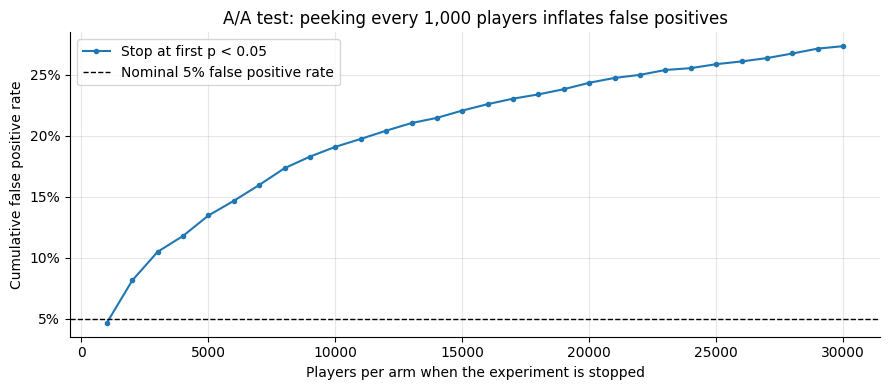

In [19]:
# 19. False positive rate grows with each peek
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(LOOKS, curves["A/A (no difference)"], marker="o", ms=3, label="Stop at first p < 0.05")
ax.axhline(0.05, c="k", ls="--", lw=1, label="Nominal 5% false positive rate")
ax.set_xlabel("Players per arm when the experiment is stopped")
ax.set_ylabel("Cumulative false positive rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_title("A/A test: peeking every 1,000 players inflates false positives")
ax.legend(); plt.tight_layout(); save_fig("05_peeking_false_positives")

**Peekings breaks p-value**. In the A/A scenario there is no real difference. However, checking the z-test after every 1,000 players and stopping at the first p < 0.05 severly inflates the false positive rate, from about 5% to about 28%, as shown in Block 19. With a single look at the planned sample size, p is roughly 5% as designed.

**The expected-loss rule (Block 18) trades speed for accuracy through threshold ε**. With ε = 0.02 pp and a true 1 pp drop (similar to our data), it stops after roughly 7,300 players per arm on average and picks the worse arm under 2% of the time. A fixed-horizon test needs about 23,700 per arm for 80% power, so that is roughly 70% fewer players. Bayesian methods are not immune to peeking either. Stopping as soon as P(B>A) > 95% also inflates errors. The defensible approach is to decide on expected loss with a threshold before the test starts.
